# Setup
If you have not run the below code in a separate Julia session, this notebook will not work.
```
using Pkg
Pkg.add("DrWatson")          
Pkg.activate("path/to/temp-tune")
Pkg.instantiate()

cd("path/to/temp-tune")
include(scriptsdir("setup_python.jl"))
```

## activate project

In [4]:
using Pkg
using DrWatson
@quickactivate "temp-tune"
println("current active project = ",Base.active_project())

current active project = /Users/pfields/Git/temp-tune/Project.toml


## setup plotting

In [5]:
include(srcdir("matplotlib_helpers.jl"))
setup_notebook_for_paper()
using_Py(true)

setup_rc_reset()
set_plot_style_for_paper(; venue="revtex")

Plot style set → venue=revtex, font='Arial'
Sizes (pt): label=10.0  tick=8.0  legend=8.0  mathtext.fontset=cm
Python     : /Users/pfields/Git/temp-tune/.conda/bin/python
Matplotlib : 3.10.8 | backend=Agg
 set plot style finished. exiting...



## other packages

In [6]:
using StatsBase, Statistics, LinearAlgebra, Printf, Random
using SpecialFunctions
using Parameters, Flux
using Optim, BenchmarkTools, JLD2, DataFrames, Graphs
using OptimizationOptimJL, Optimization
using Roots, Expectations
using Distributions
using Conda

# illustrative toy model

In [11]:
include(srcdir("two_level_toy_model.jl"))

get_dkl (generic function with 1 method)

### generate training data

In [21]:
Δtrue   =5
nlevels = 2 # always only two levels (ground and excited levels)
nexcited=20
nground=10
nsampss = 50
N_states=nground+nexcited

ees, lbls = etrues(Δtrue,nlevels,nexcited,nground)
true_probs=get_probs_2( ees )

sampless=get_samples(true_probs, nsampss, N_states );
freqs = get_freqs(sampless, lbls); # empirical distribution

### fit model

In [22]:
minlosses, Δ̂, L̂i, pfit, Δs, Lp, minl_m_to_l =fit_n_ground_and_Δ_hard_constraint( freqs, 
                                                        nsampss; make_pfit=true, λ=0);
m_to_l=reverse(sortperm(freqs));

### plot results

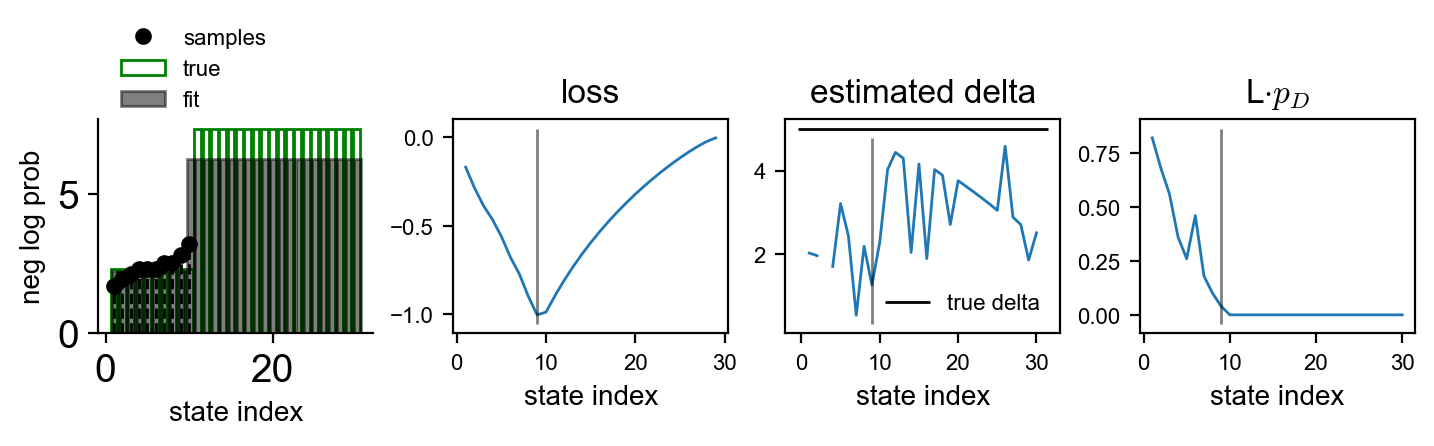

PyObject <matplotlib.legend.Legend object at 0x3422fb320>

In [36]:
fig, ax = subplots( 1,4, figsize=set_size_for_paper(2, 0.3), dpi=200, constrained_layout=true )

function plot_ptrue_and_fit_1(true_probs, pfit, freqs, most_to_least_idx, ax)
    m_to_l=most_to_least_idx
    N_states = length( true_probs )
    ax.bar(collect(1:N_states), -log.(true_probs[m_to_l]), label="true", color="none", ec="green",  );
    # bar(collect(1:N_states).+0.01, freqs, alpha=0.5, color="yellow", label="sample" );
    ax.bar(collect(1:N_states).+0.125 , -log.(pfit[m_to_l]), alpha=0.5, color="black", label="fit", ec="black");
    # plot(collect(1:N_states),1.1maximum(pfit)*(.! Bool.(L̂i)), ".")
    ax.plot(collect(1:N_states),-log.(freqs[m_to_l]), linewidth=0, marker="o", 
        color="black", markeredgecolor="k", label="samples")
    for (x, f) in zip(collect(1:N_states), -log.(freqs[m_to_l]))
        ax.vlines(x, 0, f, linestyle="--", color="k")
    end
    # ax.set_xticks(collect(1:10))
    ax.spines["right"].set_visible(false)
    ax.spines["top"].set_visible(false)
    ax.legend( frameon=false, loc=(0.05,1.))
    ax.set_xlabel("state index")# fontsize=14)
    ax.set_ylabel("neg log prob")# fontsize=14)
    ax.tick_params(axis="both", which="major", labelsize=14)
end

plot_ptrue_and_fit_1(true_probs, pfit, freqs, m_to_l, ax[1])

ax[2].plot( collect(1:N_states), minl_m_to_l )
ax[3].plot( collect(1:N_states), Δs[m_to_l] )
ax[4].plot( collect(1:N_states), Lp[m_to_l] )
ax[2].set_title("loss")
ax[3].set_title("estimated delta")
ax[4].set_title("L"*L"\cdot p_{D}")
for a in ax
    a.tick_params(axis="both", which="major")
    a.set_xlabel("state index")
end
for i in 2:4
    ax[i].vlines( findmin(minl_m_to_l)[2], ax[i].get_ylim()..., color="k", alpha=0.5)
end
# ax[4].plot(collect(1:N_states), (N_states.-collect(1:N_states))./N_states )
ax[3].hlines(Δtrue, ax[4].get_xlim()..., color="k", label="true delta")
ax[3].legend(frameon=false, loc="lower right")

### sweep tau

In [39]:
# track accuracy of L-hat

L_true = [ zeros(nground) ; ones(nexcited) ]

ground_found_idx = (L_true .== 0) .&  (L̂i .== 0)
ground_missed_idx = (L_true .== 0) .&  .! (L̂i .== 0)
excited_found_idx = (L_true .== 1) .&  (L̂i .== 1)
excited_missed_idx = (L_true .== 1) .& .! (L̂i .== 1);
idxss = [excited_found_idx, ground_missed_idx, ground_found_idx, excited_missed_idx]

dkl_keys = ["e_f","g_m","g_f","e_m"]

sub_dkls = Dict( "forward"=>[], "reversed"=>[], "data"=>[] )

for (k, id) in zip( dkl_keys, idxss )
    append!(sub_dkls["forward"], get_dkl( true_probs[id] , pfit[id] ) )
    append!(sub_dkls["reversed"], get_dkl( pfit[id], true_probs[id]  ) )
    append!(sub_dkls["data"], get_dkl(  freqs[id], pfit[id]  ) )
end

In [41]:
# perform sweep

tau_fits = collect(0.3:0.001:1.75)
p_fit_mod = similar( true_probs )

dkl_keys = ["g_f","g_m","e_f","total","e_m"]

idxss = [ground_found_idx, ground_missed_idx, excited_found_idx, fill(true, length(L̂i)), excited_missed_idx ]
sub_dkls_tau = Dict( "forward"=>Dict(zip(dkl_keys, [] for i in 1:5)), 
                    "reversed"=>Dict(zip(dkl_keys, [] for i in 1:5)),
                    "data" =>Dict(zip(dkl_keys, [] for i in 1:5)) ,
                    "itself" =>Dict(zip(dkl_keys, [] for i in 1:5))
                            )

for (k,tt) in enumerate(tau_fits )
    p_fit_mod .= get_p_toy( L̂i, Δ̂/tt);
    true_probs_mod=get_probs_2( ees./tt )
    for (j,key) in enumerate( dkl_keys ) 
        append!( sub_dkls_tau["forward"][key],  get_dkl(true_probs[idxss[j]], p_fit_mod[idxss[j]]) )
        append!( sub_dkls_tau["reversed"][key], get_dkl(p_fit_mod[idxss[j]], true_probs[idxss[j]]) )
        append!( sub_dkls_tau["data"][key], get_dkl( freqs[idxss[j]], p_fit_mod[idxss[j]]) )
        append!( sub_dkls_tau["itself"][key], get_dkl( true_probs_mod[idxss[j]], true_probs[idxss[j]] ) )
        
    end
end

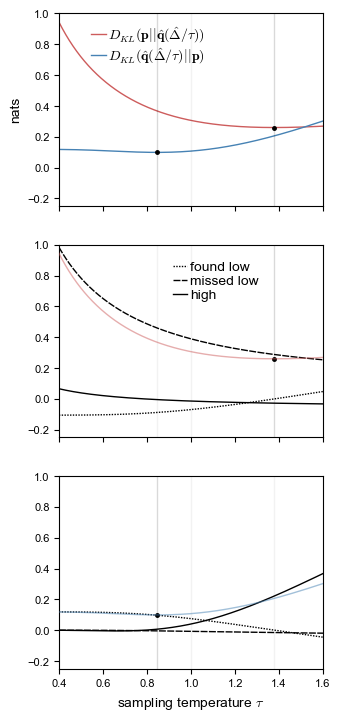

In [56]:


fig, ax = subplots(3,1,sharex=true, sharey=true, figsize=set_size_for_paper(1,2.5), dpi=100)
function toy_tau_plots(ax; ylabelsize=10,xlabelsize=10, ticklabelsize=10, 
        ax1_leg_loc=(0.1,0.1), ax2_leg_loc=(0.41,0.675), ax1legsize=10,ax2legsize=10)
    lstyles = [(0,(1,1)),(0,(5,1)), "-","-",""]
    zords = [10,11,8,20]
    alphs=[1,1,1.,0.5]
    # ax[1].set_ylim(-0.4,2.)
    ax[1].plot( tau_fits, sub_dkls_tau["forward"]["total"], 
        color="indianred", label = L"D_{KL}(\mathbf{p}||\hat \mathbf{q}(\hat{\Delta}/\tau ))")
    ax[1].plot( tau_fits, sub_dkls_tau["reversed"]["total"], 
        color="steelblue", label= L"D_{KL}(\hat \mathbf{q}(\hat\Delta/\tau) ||\mathbf{p})")

    ax[1].legend(frameon=false, loc=ax1_leg_loc, fontsize=ax1legsize, 
        handletextpad=0.2, handlelength=1.05, labelspacing=0.1)
    
    # ax[1].set_ylim(-0.25,2)
    # ax[1].set_xlim(0.4,1.6)
    plt.sca(ax[1])

    colorss = ["k", "k","k","indianred", "grey"]
    lls=[]
    for (j,key) in enumerate( dkl_keys ) 
        (j == 5 ) && continue 
        append!(lls,ax[2].plot( tau_fits, sub_dkls_tau["forward"][key], c=colorss[j],  label=key,
            linestyle=lstyles[j], zorder=zords[j], alpha=alphs[j] ))
    end
    tau_min_red, dkl_min_val = (tau_fits[findmin(sub_dkls_tau["forward"]["total"])[2]], 
        findmin(sub_dkls_tau["forward"]["total"])[1])
    ax[2].plot( tau_min_red , dkl_min_val, ".k" )
    ax[2].vlines( tau_min_red, -5,5, "k", alpha=0.15)
    # ax[3].legend( (lls[1:3]), ["found ground", "missed ground", "excited"], frameon=false, handlelength=0.4,
    #     handletextpad=0.25, loc=ax2_leg_loc, fontsize=ax2legsize )

    # plt.grid("on")

    colorss = ["k", "k","k","steelblue", "grey"]
    lls=[]
    for (j,key) in enumerate( dkl_keys ) 
        (j == 5 ) && continue 
        append!(lls, ax[3].plot( tau_fits, sub_dkls_tau["reversed"][key], c=colorss[j],  label=key,
            linestyle=lstyles[j], zorder=zords[j], alpha=alphs[j] ))
    end
    tau_min_blue, dkl_min_val_b = (tau_fits[findmin(sub_dkls_tau["reversed"]["total"])[2]], 
        findmin(sub_dkls_tau["reversed"]["total"])[1])
    plt.sca(ax[1])
    ax[3].plot( tau_min_blue , dkl_min_val_b, ".k")
    ax[3].vlines( tau_min_blue, -5,5, "k", alpha=0.15)
    ax[3].vlines( tau_min_red, -5,5, "k", alpha=0.05)
    ax[2].legend( (lls[1:3]), ["found low", "missed low", "high"], frameon=false, handlelength=1.05,
        handletextpad=0.2, loc=ax2_leg_loc, fontsize=ax2legsize, labelspacing=0.1 )


    ax[3].set_xlabel("sampling temperature "*L"\tau", fontsize=xlabelsize)
    # legend()

    for a in ax
        a.vlines(1, -5,5, "k", alpha=0.05, lw=1)
    end

    plt.sca(ax[1])
    
    ax[1].set_ylabel("nats", fontsize=ylabelsize)
    ax[1].plot( tau_min_red , dkl_min_val, ".k" )
    ax[1].vlines( tau_min_red, -5,5, "k", alpha=0.15)
    ax[1].vlines( tau_min_blue, -5,5, "k", alpha=0.15)
    ax[1].plot( tau_min_blue , dkl_min_val_b, ".k")
    ax[2].vlines( tau_min_blue, -5,5, "k", alpha=0.05)

    ax[1].set_ylim(-0.25,1.)
    ax[1].set_xlim(0.4,1.6)
    
    for a in ax
        a.tick_params(axis="both")#, labelsize=ticklabelsize)
        # a.minorticks_on()
    end
end

toy_tau_plots(ax, ax1_leg_loc=(0.1,0.7), ax2_leg_loc=(0.41,0.675))